# How the size of W shapes a layer's output

The batch-norm report showed that the init scale decides whether tanh layers saturate or fade out.
This notebook shows *why*, step by step, using random data so every number can be checked by hand.

In [1]:
import torch
import matplotlib.pyplot as plt
%matplotlib inline

torch.manual_seed(42)

# one color per weight scale, used in every plot below
SMALL, RIGHT, LARGE = '#1baf7a', '#2a78d6', '#eb6834'

## 1. One linear layer: `y = x @ W`

Each output neuron is a sum of `fan_in` products:

$$y_j = x_1 W_{1j} + x_2 W_{2j} + \dots + x_n W_{nj}$$

If `x ~ N(0, 1)` and `W ~ N(0, s²)` are independent, each product has variance $s^2$, and the variances of independent terms add up:

$$\mathrm{Var}(y) = n \cdot s^2 \quad\Rightarrow\quad \mathrm{std}(y) = s \cdot \sqrt{n}$$

So **the output std is the weight std times the square root of fan_in**. Let's check it with `fan_in = 100`, where $\sqrt{n} = 10$.

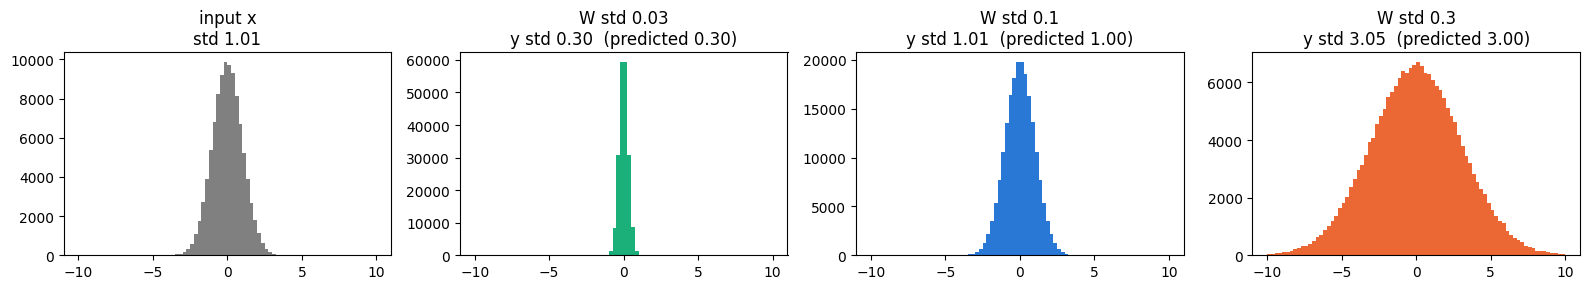

In [2]:
n = 100                       # fan_in
x = torch.randn(1000, n)      # 1000 examples, std 1
bins = torch.linspace(-10, 10, 81)

fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharex=True)
axes[0].hist(x.flatten(), bins, color='gray')
axes[0].set_title(f'input x\nstd {x.std():.2f}')

for ax, s, color in zip(axes[1:], [0.03, 0.1, 0.3], [SMALL, RIGHT, LARGE]):
    W = torch.randn(n, 200) * s
    y = x @ W
    ax.hist(y.flatten(), bins, color=color)
    ax.set_title(f'W std {s}\ny std {y.std():.2f}  (predicted {s * n**0.5:.2f})')
plt.tight_layout()

The input is the same in all four plots. Only the scale of `W` changes, and the output gets 0.3x, 1x or 3x as wide as the input.

**fan_in matters just as much.** Here is plain `torch.randn` (s = 1) with different fan_in:

In [3]:
for n in [10, 30, 100, 1000]:
    x = torch.randn(1000, n)
    y = x @ torch.randn(n, 200)
    print(f'fan_in {n:4d}:  y std {y.std():6.2f}   predicted sqrt(n) = {n**0.5:6.2f}')

fan_in   10:  y std   3.20   predicted sqrt(n) =   3.16
fan_in   30:  y std   5.42   predicted sqrt(n) =   5.48
fan_in  100:  y std  10.07   predicted sqrt(n) =  10.00
fan_in 1000:  y std  31.58   predicted sqrt(n) =  31.62


`fan_in = 30` is the first layer of our names model (3 characters x 10-dim embedding). That is why `W1 = torch.randn(30, 200)` produced
pre-activations with std ≈ 5.5, the wide distribution in the report.

## 2. The fix: s = 1 / √fan_in

If `s = 1 / sqrt(n)`, then `s * sqrt(n) = 1` for **any** fan_in. That is where the `/ fan_in**0.5` in Kaiming init comes from.

In [4]:
for n in [10, 30, 100, 1000]:
    x = torch.randn(1000, n)
    y = x @ (torch.randn(n, 200) / n**0.5)
    print(f'fan_in {n:4d}:  y std {y.std():.2f}')

fan_in   10:  y std 0.99
fan_in   30:  y std 1.01
fan_in  100:  y std 1.00
fan_in 1000:  y std 1.00


## 3. Add tanh

tanh is close to `x` near zero and flat at ±1 once `|x|` goes past ~2. So what comes **out** of tanh depends on how wide the distribution going **in** is.
Same three weight scales as before (`fan_in = 100`). Top row is before tanh, bottom row after it:

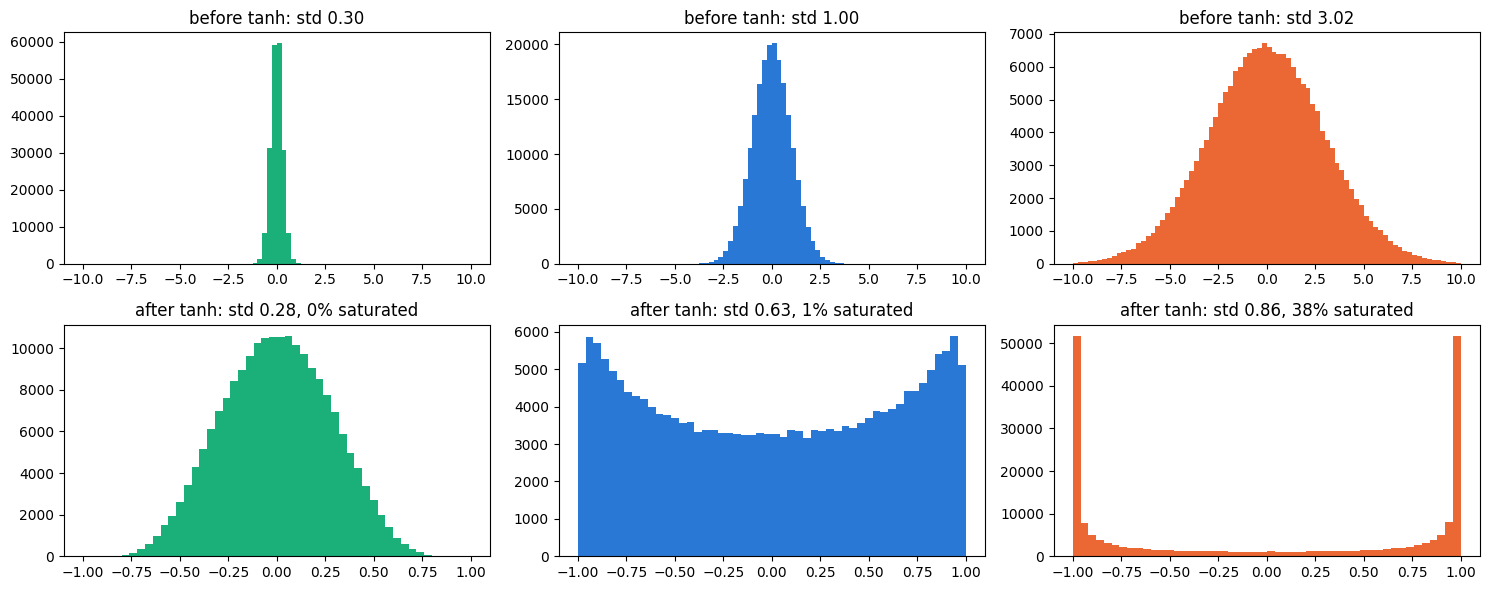

In [5]:
n = 100
x = torch.randn(1000, n)

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, s, color in zip(range(3), [0.03, 0.1, 0.3], [SMALL, RIGHT, LARGE]):
    y = x @ (torch.randn(n, 200) * s)
    h = torch.tanh(y)
    saturated = (h.abs() > 0.99).float().mean()

    axes[0, col].hist(y.flatten(), torch.linspace(-10, 10, 81), color=color)
    axes[0, col].set_title(f'before tanh: std {y.std():.2f}')
    axes[1, col].hist(h.flatten(), torch.linspace(-1, 1, 51), color=color)
    axes[1, col].set_title(f'after tanh: std {h.std():.2f}, {saturated:.0%} saturated')
plt.tight_layout()

- **std 0.3 going in:** tanh is almost linear in that range, so the output is the same narrow distribution. Nothing saturates, but the signal is weak.
- **std 1 going in:** the output spreads over (-1, 1) and very little saturates. The std still drops from 1 to about 0.6, because tanh always squashes.
- **std 3 going in:** a big share (almost 40 %) piles up at ±1. Those units are saturated and pass back almost no gradient.

Because tanh always shrinks the std, Kaiming init for tanh multiplies by a **gain of 5/3** to make up for it: `W = torch.randn(n, m) * (5/3) / n**0.5`.

## 4. Stack layers: the effect compounds

Every layer multiplies the std by roughly the same factor, so after `L` layers the factor is raised to the power `L`.
With linear layers only, the std after layer `L` is exactly $(s\sqrt{n})^L$:

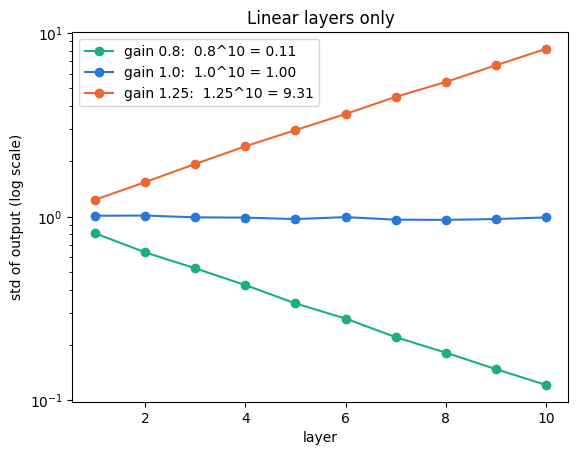

In [6]:
def run_stack(gain, nonlin=None, n_layers=10, n=100):
    # pushes random data through n_layers layers with W = randn * gain / sqrt(n)
    x = torch.randn(1000, n)
    outs = []
    for _ in range(n_layers):
        x = x @ (torch.randn(n, n) * gain / n**0.5)
        if nonlin is not None:
            x = nonlin(x)
        outs.append(x)
    return outs

layers = range(1, 11)
for gain, color in [(0.8, SMALL), (1.0, RIGHT), (1.25, LARGE)]:
    stds = [o.std() for o in run_stack(gain)]
    plt.plot(layers, stds, 'o-', color=color, label=f'gain {gain}:  {gain}^10 = {gain**10:.2f}')
plt.yscale('log')
plt.xlabel('layer')
plt.ylabel('std of output (log scale)')
plt.title('Linear layers only')
plt.legend();

A per-layer error of only 20-25 % turns into a factor of ~10 after ten layers. The signal (and, on the backward pass, the gradient) either vanishes or explodes.

**Now with tanh between the layers.** tanh caps the std at 1, so nothing explodes. But too large a gain saturates every layer, and too small a gain lets the signal fade:

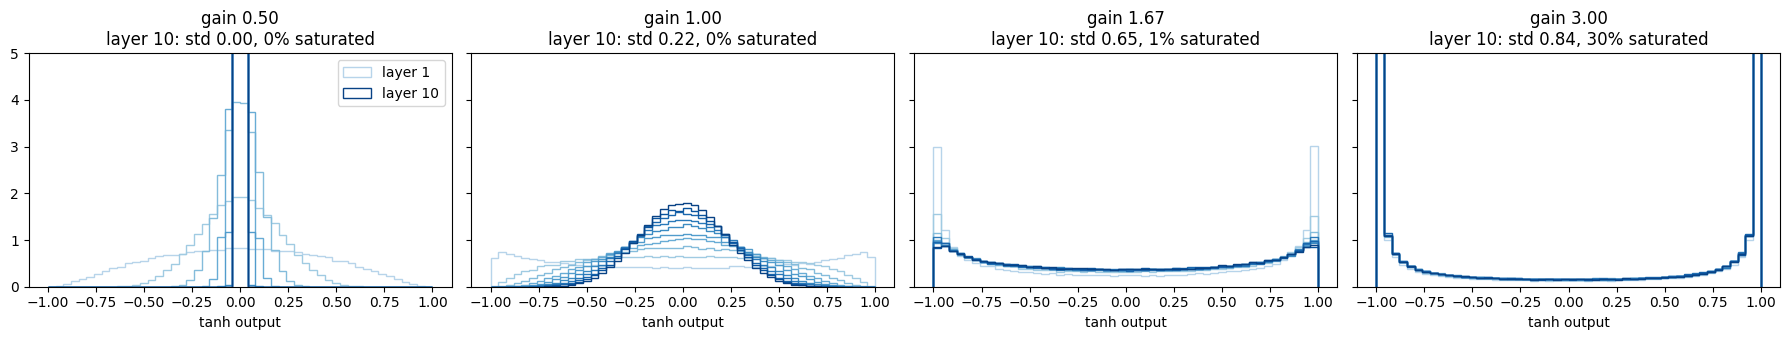

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
for ax, gain in zip(axes, [0.5, 1.0, 5/3, 3.0]):
    outs = run_stack(gain, nonlin=torch.tanh)
    for i, h in enumerate(outs):
        ax.hist(h.flatten(), torch.linspace(-1, 1, 51), histtype='step', density=True,
                color=plt.cm.Blues(0.3 + 0.7 * i / len(outs)), label=f'layer {i+1}' if i in (0, len(outs) - 1) else None)
    last = outs[-1]
    ax.set_title(f'gain {gain:.2f}\nlayer 10: std {last.std():.2f}, {(last.abs() > 0.99).float().mean():.0%} saturated')
    ax.set_xlabel('tanh output')
axes[0].set_ylim(0, 5)
axes[0].legend()
plt.tight_layout()

(Light blue = layer 1, dark blue = layer 10. The y-axis is cut at 5 so the tall spikes don't flatten the other curves.)

- **gain 0.5:** each layer shrinks the signal, so deep layers are squeezed toward 0.
- **gain 1:** sounds right, but tanh still shrinks the std a bit at every layer, so the signal slowly fades.
- **gain 5/3:** the squashing is compensated, and every layer looks about the same.
- **gain 3:** about 30 % of the units in every layer are stuck at ±1, and much of the rest is close to it.

## 5. Where batch norm comes in

Kaiming init *predicts* the right scale from fan_in and the nonlinearity. Batch norm *measures* the std of each neuron over the batch and divides it out.
Here is the same stack with a deliberately bad gain of 3, once with normalization before each tanh and once without:

In [8]:
def batchnorm(x):
    return (x - x.mean(0, keepdim=True)) / x.std(0, keepdim=True)

plain = run_stack(3.0, nonlin=torch.tanh)
normed = run_stack(3.0, nonlin=lambda x: torch.tanh(batchnorm(x)))

for name, outs in [('gain 3, plain     ', plain), ('gain 3, batch norm', normed)]:
    sat = [f'{(h.abs() > 0.99).float().mean():.0%}' for h in outs]
    print(f'{name}  saturated per layer: {sat}')

gain 3, plain       saturated per layer: ['37%', '30%', '29%', '29%', '28%', '30%', '30%', '30%', '29%', '28%']
gain 3, batch norm  saturated per layer: ['1%', '1%', '1%', '1%', '1%', '1%', '1%', '1%', '1%', '1%']


With normalization, the scale of `W` doesn't matter anymore: every layer gets a std-1 input, no matter what gain was used.

### Summary

| what you change | effect on the output std |
|---|---|
| weight std `s` | multiplies it by `s` |
| fan_in `n` | multiplies it by `√n` |
| tanh | shrinks it, and saturates at ±1 when the input is wide |
| `L` stacked layers | the per-layer factor gets raised to the power `L` |

Kaiming init sets `s = gain / √n` so that the per-layer factor is about 1 at step 0. Batch norm enforces it at every step.